<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSjLbUpiZ3l_Wq8OImd07QQtBHoW8Z9Tp13xZUVq_lXWe5-VkMZms9iSVI&s=10" alt="Lionel Messi" width="300">

# Lionel Messi: Goals analysis

This notebook explores a complete record of Lionel Messi's club goals. 

Dataset: [Messi All Goals GOAT on Kaggle](https://www.kaggle.com/datasets/sigmaborov/messi-all-goals-goat).

### Topics
- Load and inspect a football events dataset
- Check missing values and prepare analysis columns
- Look for patterns across seasons, competitions, goal types, venues, and match minutes
- Compare goals by season and competition
- Explore when and how goals were scored
- Compare home and away goals

**Question for the lesson:** What patterns can we find in Messi's goals across his career?

> **Estimated time: 60 min**

## 1 · Import libraries and load the data

The CSV file should be in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


%matplotlib inline

In [2]:
messi_goals = pd.read_csv('lionel_messi_goals.csv')
print('Rows and columns:', messi_goals.shape)

Rows and columns: (790, 16)


In [3]:
messi_goals

,competition,match_stage,date,venue,club,opponent,match_score,player_position,goal_minute,score_at_goal,goal_type,assist_player,season,goal_decade,is_home_goal,goal_minute_bucket
0,2ª B - Grupo III,2,2004-09-05,Home,FC Barcelona B,Girona FC,1:2,LW,65,1:2,Left-footed shot,Dani Fernández,2004-05,2000s,True,61-75
1,2ª B - Grupo III,4,2004-09-18,Home,FC Barcelona B,RCD Espanyol B,2:0,LW,88,2:0,Left-footed shot,Dani Fernández,2004-05,2000s,True,76-90
2,2ª B - Grupo III,10,2004-10-31,Away,FC Barcelona B,Villajoyosa CF,2:1,AM,2,0:1,Not reported,Not Applicable,2004-05,2000s,False,0-15
3,2ª B - Grupo III,14,2004-11-28,Away,FC Barcelona B,UE Figueres,2:2,AM,20,0:1,Not reported,Not Applicable,2004-05,2000s,False,16-30
4,2ª B - Grupo III,17,2004-12-19,Home,FC Barcelona B,CD Alcoyano,2:0,CF,40,2:0,Left-footed shot,Not Applicable,2004-05,2000s,True,31-45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,MLS Cup Playoffs,First Round,2025-11-09,Home,Inter Miami CF,Nashville SC,4:0,CF,39,2:0,Left-footed shot,Mateo Silvetti,2025-26,2020s,True,31-45
786,MLS Cup Playoffs,Quarter-Finals,2025-11-23,Away,Inter Miami CF,FC Cincinnati,0:4,CF,19,0:1,Header,Mateo Silvetti,2025-26,2020s,False,16-30
787,MLS,2,2026-03-02,Away,Inter Miami CF,Orlando City SC,2:4,SS,57,2:2,Left-footed shot,Telasco Segovia,2025-26,2020s,False,46-60
788,MLS,2,2026-03-02,Away,Inter Miami CF,Orlando City SC,2:4,SS,90,2:4,Direct free kick,Not Applicable,2025-26,2020s,False,76-90


## 2 · Inspect and prepare the columns

Before making charts, check data types and missing values. We also convert dates and make sure the goal minute is numeric.

In [4]:
messi_goals.info()

<class 'pandas.DataFrame'>
RangeIndex: 790 entries, 0 to 789
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   competition         790 non-null    str  
 1   match_stage         790 non-null    str  
 2   date                790 non-null    str  
 3   venue               790 non-null    str  
 4   club                790 non-null    str  
 5   opponent            790 non-null    str  
 6   match_score         790 non-null    str  
 7   player_position     790 non-null    str  
 8   goal_minute         790 non-null    int64
 9   score_at_goal       790 non-null    str  
 10  goal_type           790 non-null    str  
 11  assist_player       790 non-null    str  
 12  season              790 non-null    str  
 13  goal_decade         790 non-null    str  
 14  is_home_goal        790 non-null    bool 
 15  goal_minute_bucket  790 non-null    str  
dtypes: bool(1), int64(1), str(14)
memory usage: 93.5 KB


In [5]:
print('Missing values:')
messi_goals.isna().sum()

Missing values:


competition           0
match_stage           0
date                  0
venue                 0
club                  0
opponent              0
match_score           0
player_position       0
goal_minute           0
score_at_goal         0
goal_type             0
assist_player         0
season                0
goal_decade           0
is_home_goal          0
goal_minute_bucket    0
dtype: int64

In [6]:
messi_goals['date'] = pd.to_datetime(messi_goals['date'])
messi_goals['goal_minute'] = pd.to_numeric(messi_goals['goal_minute'], errors='coerce')
messi_goals['is_home_goal'] = messi_goals['is_home_goal'].astype(str).str.lower().eq('true')

messi_goals[['date', 'competition', 'goal_minute', 'goal_type', 'venue']].head()

,date,competition,goal_minute,goal_type,venue
0,2004-09-05,2ª B - Grupo III,65,Left-footed shot,Home
1,2004-09-18,2ª B - Grupo III,88,Left-footed shot,Home
2,2004-10-31,2ª B - Grupo III,2,Not reported,Away
3,2004-11-28,2ª B - Grupo III,20,Not reported,Away
4,2004-12-19,2ª B - Grupo III,40,Left-footed shot,Home


## 3 · Goals by season

A season-level count helps us see the periods with the most goals. We keep the chronological order instead of sorting only by count.

In [7]:
season_order = sorted(messi_goals['season'].unique(), key=lambda season: int(season[:4]))
messi_goals_by_season = messi_goals.groupby('season').size().reindex(season_order)
messi_goals_by_season.rename('goals').to_frame()

,goals
season,
2004-05,7
2005-06,8
2006-07,17
2007-08,16
2008-09,38
2009-10,47
2010-11,53
2011-12,73
2012-13,60


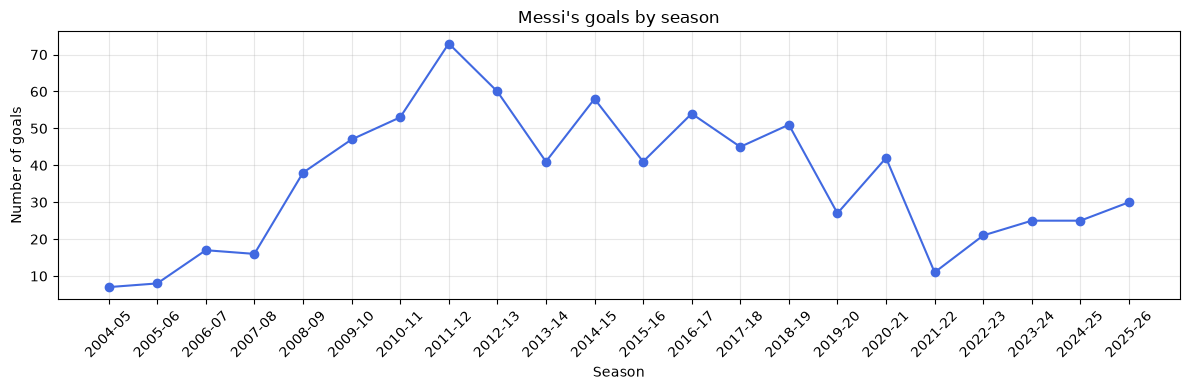

In [8]:
plt.figure(figsize=(12, 4))
plt.plot(messi_goals_by_season.index, messi_goals_by_season.values, marker='o', color='royalblue')
plt.title("Messi's goals by season")
plt.xlabel('Season')
plt.ylabel('Number of goals')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4 · Which competitions contributed the most goals?

A ranked bar chart makes it easy to compare domestic leagues, cups, and international competitions.

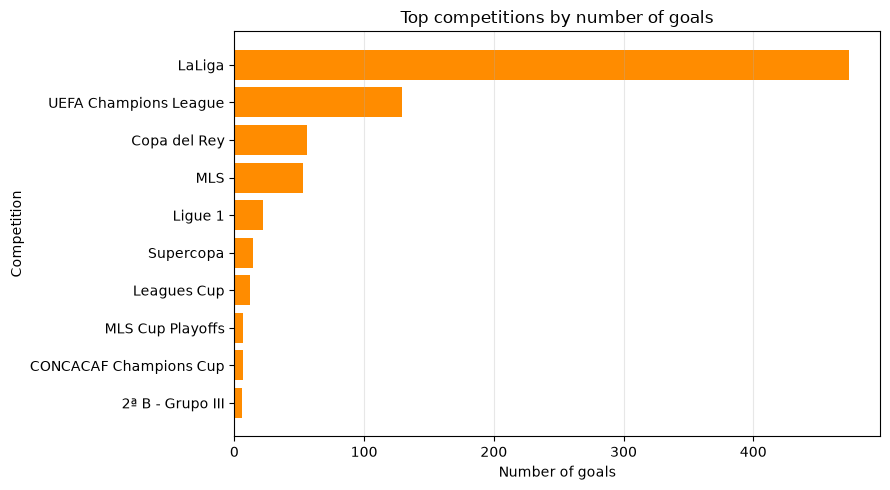

In [9]:
competition_counts = messi_goals['competition'].value_counts().head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(competition_counts.index, competition_counts.values, color='darkorange')
plt.title('Top competitions by number of goals')
plt.xlabel('Number of goals')
plt.ylabel('Competition')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 5 · When did the goals happen?

The dataset already groups minutes into buckets. This lets us compare early goals, goals around half-time, and late goals.

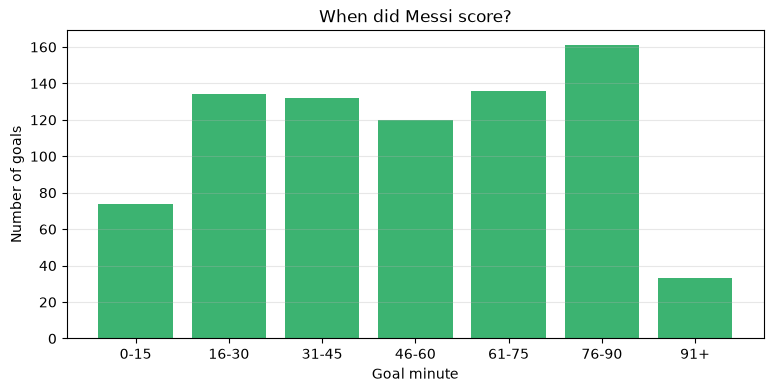

In [10]:
minute_buckets = ['0-15', '16-30', '31-45', '46-60', '61-75', '76-90', '91+']
minute_counts = messi_goals['goal_minute_bucket'].value_counts().reindex(minute_buckets)

plt.figure(figsize=(9, 4))
plt.bar(minute_counts.index, minute_counts.values, color='mediumseagreen')
plt.title("When did Messi score?")
plt.xlabel('Goal minute')
plt.ylabel('Number of goals')
plt.grid(axis='y', alpha=0.3)
plt.show()

## 6 · How were the goals scored?

Goal type includes shots, penalties, free kicks, headers, and other categories. We show the most frequent types and group the rest as **Other**.

In [11]:
goal_type_counts = messi_goals['goal_type'].value_counts()
top_types = goal_type_counts.head(5).copy()
top_types['Other'] = goal_type_counts.iloc[5:].sum()
top_types = top_types.sort_values(ascending=False)

goal_type_counts.rename('goals').to_frame().head(10)

,goals
goal_type,
Left-footed shot,493
Right-footed shot,93
Penalty,88
Direct free kick,59
Header,28
Tap-in,10
Not reported,5
Solo run,5
Penalty rebound,3


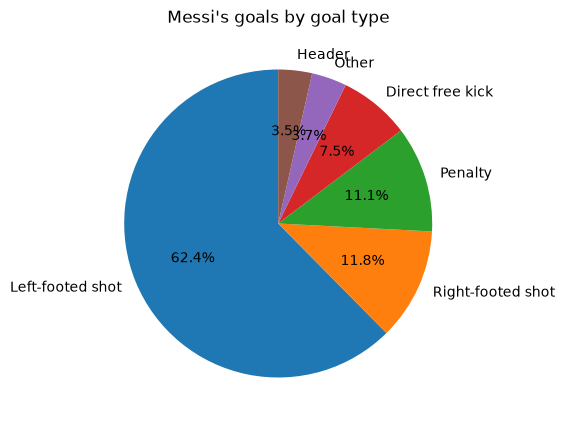

In [12]:
plt.figure(figsize=(8, 5))
plt.pie(
    top_types.values,
    labels=top_types.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Messi's goals by goal type")
plt.show()

## 7 · Home versus away goals

A simple comparison can show whether the goals in this dataset were more common at home or away.

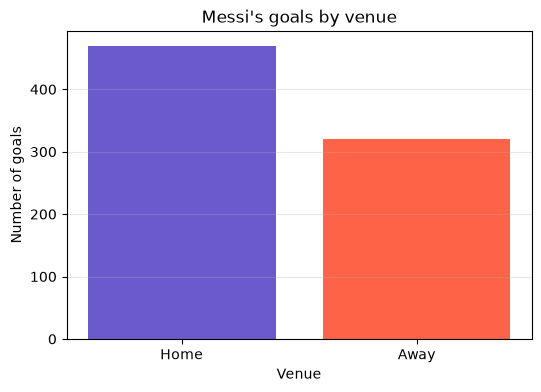

In [13]:
venue_counts = messi_goals['venue'].value_counts().reindex(['Home', 'Away'])

plt.figure(figsize=(6, 4))
plt.bar(venue_counts.index, venue_counts.values, color=['slateblue', 'tomato'])
plt.title("Messi's goals by venue")
plt.xlabel('Venue')
plt.ylabel('Number of goals')
plt.grid(axis='y', alpha=0.3)
plt.show()

## Key takeaways

- Pandas makes it easy to count goals by season, competition, type, and venue.
- A line chart shows change over seasons; bar charts compare categories; a pie chart shows composition.
- The `goal_minute_bucket` column turns individual minutes into an interpretable distribution.
- Always check the data dictionary and the meaning of each column before interpreting a chart.